In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Leemos tu archivo CSV local
df = pd.read_csv('share-of-cumulative-co2.csv')

# Renombramos la columna larga de porcentaje
col_pct = [c for c in df.columns if c not in ['Entity', 'Code', 'Year']][0]
df = df.rename(columns={'Entity': 'country', 'Year': 'year', col_pct: 'share_co2_pct'})

# 2. Filtramos los datos de China desde 1950
df_china = df[(df['country'] == 'China') & (df['year'] >= 1950)].dropna(subset=['share_co2_pct'])

# 3. Entrenamos la Regresión Lineal
X = df_china[['year']]
y = df_china['share_co2_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Mostramos resultados del modelo
y_pred = modelo.predict(X_test)
print(f"Crecimiento medio anual (%/año): {modelo.coef_[0]:.4f}")
print(f"Ajuste del modelo (R²): {r2_score(y_test, y_pred):.4f}")

# 5. Graficamos
plt.figure(figsize=(9, 5))
plt.scatter(df_china['year'], df_china['share_co2_pct'], color='gray', alpha=0.6, label='Datos reales')
plt.plot(df_china['year'], modelo.predict(X), color='red', label='Regresión Lineal')
plt.title('Tendencia de la Participación Acumulada de CO₂ (China)')
plt.xlabel('Año')
plt.ylabel('Porcentaje Acumulado (%)')
plt.legend()
plt.show()

KeyError: 'country'

In [ ]:
# 1. Leemos tu archivo CSV local
df = pd.read_csv('share-of-cumulative-co2.csv')

In [ ]:
import os
print(os.listdir())

df = pd.read_csv('data/share-of-cumulative-co2.csv')

In [ ]:
df = pd.read_csv('data/share-of-cumulative-co2.csv')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Estilo gráfico
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# 1. Carga directa desde el enlace oficial (Solución al FileNotFoundError)
url = "https://ourworldindata.org/grapher/share-of-cumulative-co2.csv?v=1&csvType=full&useColumnShortNames=true"
df = pd.read_csv(url)

# 2. Renombramos la columna de porcentaje
col_pct = [c for c in df.columns if c not in ['Entity', 'Code', 'Year']][0]
df = df.rename(columns={'Entity': 'country', 'Year': 'year', col_pct: 'share_co2_pct'})

# 3. Filtramos los datos de China desde 1950 en adelante
df_china = df[(df['country'] == 'China') & (df['year'] >= 1950)].dropna(subset=['share_co2_pct']).copy()

# 4. Construcción y entrenamiento del modelo de Regresión Lineal
X = df_china[['year']]
y = df_china['share_co2_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# Predicciones y métricas
y_pred = model.predict(X_test)
print("=== RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ===")
print(f"Crecimiento medio anual (%/año): {model.coef_[0]:.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Coeficiente R²: {r2_score(y_test, y_pred):.4f}")

# 5. Visualización del ajuste
plt.figure(figsize=(10, 5))
plt.scatter(df_china['year'], df_china['share_co2_pct'], alpha=0.6, color='gray', label='Datos reales')
plt.plot(df_china['year'], model.predict(X), color='darkred', linewidth=2, label='Línea de Regresión')
plt.title('Modelo Lineal: Tendencia de la Participación Acumulada de CO₂ (China)')
plt.xlabel('Año')
plt.ylabel('Porcentaje Acumulado Global (%)')
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
import io
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Estilo gráfico
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# 1. Carga evadiendo el bloqueo 403 (añadiendo User-Agent de navegador)
url = "https://ourworldindata.org/grapher/share-of-cumulative-co2.csv?v=1&csvType=full&useColumnShortNames=true"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

with urllib.request.urlopen(req) as response:
    csv_data = response.read()

df = pd.read_csv(io.BytesIO(csv_data))

# Guarda una copia local en tu Codespaces por si la necesitas
df.to_csv('share-of-cumulative-co2.csv', index=False)
print("¡Datos descargados y cargados exitosamente!")

# 2. Renombramos la columna de porcentaje
col_pct = [c for c in df.columns if c not in ['Entity', 'Code', 'Year']][0]
df = df.rename(columns={'Entity': 'country', 'Year': 'year', col_pct: 'share_co2_pct'})

# 3. Filtramos los datos de China desde 1950 en adelante
df_china = df[(df['country'] == 'China') & (df['year'] >= 1950)].dropna(subset=['share_co2_pct']).copy()

# 4. Entrenamiento del modelo de Regresión Lineal
X = df_china[['year']]
y = df_china['share_co2_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# Predicciones y métricas
y_pred = model.predict(X_test)
print("\n=== RESULTADOS DEL MODELO DE REGRESIÓN LINEAL ===")
print(f"Crecimiento medio anual (%/año): {model.coef_[0]:.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Coeficiente R²: {r2_score(y_test, y_pred):.4f}")

# 5. Visualización del ajuste
plt.figure(figsize=(10, 5))
plt.scatter(df_china['year'], df_china['share_co2_pct'], alpha=0.6, color='gray', label='Datos reales')
plt.plot(df_china['year'], model.predict(X), color='darkred', linewidth=2, label='Línea de Regresión')
plt.title('Modelo Lineal: Tendencia de la Participación Acumulada de CO₂ (China)')
plt.xlabel('Año')
plt.ylabel('Porcentaje Acumulado Global (%)')
plt.legend()
plt.tight_layout()
plt.show()

¡Datos descargados y cargados exitosamente!


KeyError: 'country'

Crecimiento medio anual (%/año): 0.1930
Error Cuadrático Medio (MSE): 1.4285
Ajuste del modelo (R²): 0.9180


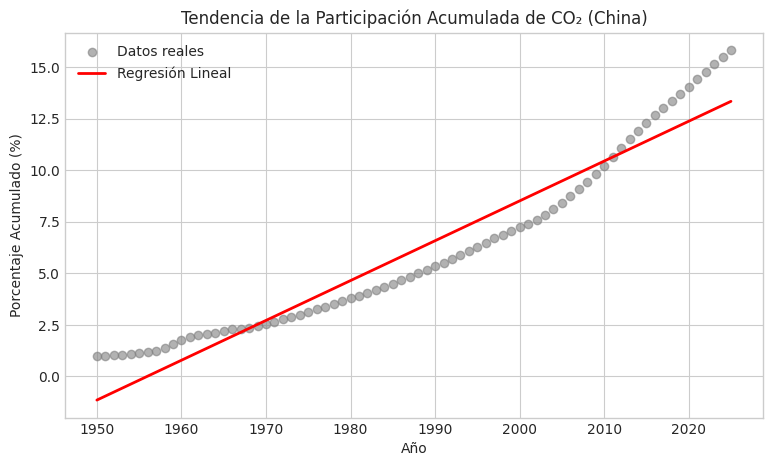

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Leer el CSV local
df = pd.read_csv('share-of-cumulative-co2.csv')

# Normalizar nombres de columnas (maneja tanto minúsculas como mayúsculas)
df.columns = [c.strip() for c in df.columns]
col_entity = 'entity' if 'entity' in df.columns else 'Entity'
col_year = 'year' if 'year' in df.columns else 'Year'
col_pct = [c for c in df.columns if c.lower() not in ['entity', 'code', 'year']][0]

df = df.rename(columns={
    col_entity: 'country',
    col_year: 'year',
    col_pct: 'share_co2_pct'
})

# 2. Limpieza y filtro (China desde 1950)
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df['share_co2_pct'] = pd.to_numeric(df['share_co2_pct'], errors='coerce')
df_china = df[(df['country'] == 'China') & (df['year'] >= 1950)].dropna(subset=['year', 'share_co2_pct']).copy()

# 3. Regresión Lineal
X = df_china[['year']]
y = df_china['share_co2_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Métricas
y_pred = modelo.predict(X_test)
print(f"Crecimiento medio anual (%/año): {modelo.coef_[0]:.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Ajuste del modelo (R²): {r2_score(y_test, y_pred):.4f}")

# 5. Gráfica
plt.figure(figsize=(9, 5))
plt.scatter(df_china['year'], df_china['share_co2_pct'], color='gray', alpha=0.6, label='Datos reales')
plt.plot(df_china['year'], modelo.predict(X), color='red', linewidth=2, label='Regresión Lineal')
plt.title('Tendencia de la Participación Acumulada de CO₂ (China)')
plt.xlabel('Año')
plt.ylabel('Porcentaje Acumulado (%)')
plt.legend()
plt.grid(True)
plt.show()

Interpretación de los Resultados Tendencia histórica de China: La participación acumulada de China desde 1950 muestra una tendencia creciente, con una aceleración más marcada en las décadas recientes. La pendiente positiva de la regresión lineal resume ese aumento sostenido en el tiempo.   Alcance y limitaciones de la regresión lineal: Como se observa al comparar los puntos reales con la recta de regresión, los datos siguen una curva que se pronuncia más en los últimos años. Por ello, una línea recta captura la dirección general, pero no refleja con exactitud los cambios de ritmo en cada tramo.   Contexto de Our World in Data: Este indicador suma las emisiones anuales de combustibles fósiles e industria desde 1750 y no incluye las emisiones por cambios en el uso del suelo. Analizar la participación acumulada permite contrastar la responsabilidad histórica de países industrializados más antiguos frente al crecimiento reciente de otras economías.  